# Coarsening from the 700p shots (2026-08-19)

Same pipeline as `shot_images.ipynb`, run on `700p_shots/2026_08_19/`.

What is different from the 126-shot `coarsening_data` set:

| | `coarsening_data` | `700p_shots/2026_08_19` |
|---|---|---|
| shots | 129 | 729 usable (752 files) |
| times | 26 (0-800 ms) | 29 (0-2000 ms) |
| shots per time | ~5 | **25-26** |
| crop box | `[130, 400, 105, 380]` (hard-coded) | measured from the t = 0 mean (below) |

The many-shots-per-time difference is the important one: the per-time PCA is
built from ~25 samples instead of ~5, so PC1 is a far better-determined
estimate of the shared envelope and the self-subtraction bias is ~1/25
instead of ~1/5.

Time map (matches the sequence log in `2026_08_19_coarsening.ipynb`, and
verified against `BEC_TIME_SEQ[6]` in every file):
seq 6 -> 0 ms; 7 -> 800; 9-12 -> 20,30,40,50; 14 -> 32,34,36,38;
15 -> 60,70,80,90,100; 16 -> 25; 18 -> 150,200,250,300;
19 -> 400,500,600,700; 20 -> 1000,1333,1667,2000; 21 -> 45.

In [11]:
import glob
import os
import re
import sys

import h5py
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter, rotate

%matplotlib inline

SCRIPT_DIR = os.path.dirname(globals().get("__file__", "")) or os.path.abspath("")
if os.path.basename(SCRIPT_DIR) != "scripts":
    SCRIPT_DIR = "/Users/nolexnol/quantum_sim/scripts"

sys.path.insert(0, os.path.join(SCRIPT_DIR, "..", "src"))
from quantum_sim.file import ShotFile

DATA_DIR = os.path.join(SCRIPT_DIR, "700p_shots", "2026_08_19")

CAM = "cam6"
TIME_INDEX = 6        # swept element of BEC_TIME_SEQ (seconds)
CROP_HALF = 130       # half-width of the square cut around the cloud centroid
ROT_ANGLE = 45        # deg; the box sits diamond-wise in the raw frame

# Pixel size. The 08/19 notebook and shot_images cell 3 both use 0.66 um/px.
# Sanity check below: the box measures ~173 px across in BOTH datasets, so a
# 113 um box implies 113/173 = 0.653 um/px. 0.696 would make the box 120 um.
# L scales linearly with this, so switching is a one-line change.
PIXEL_UM = 0.66

NAME_RE = re.compile(
    r"^(?P<seq>\d{4}-\d{2}-\d{2}_\d{4})_bec_box2_(?P<idx>\d+)"
    r"(?:_rep(?P<rep>\d+))?\.h5$"
)


def shot_paths():
    """Every bec_box2 .h5 in DATA_DIR that actually contains camera frames.

    23 of the 752 files (the last rep of each sequence run) were written
    without an /images group -- aborted shots. They are dropped here.
    """
    keep, dead = [], []
    for path in sorted(glob.glob(os.path.join(DATA_DIR, "*bec_box2*.h5"))):
        if not NAME_RE.match(os.path.basename(path)):
            continue
        with h5py.File(path, "r") as f:
            (keep if "images" in f else dead).append(path)
    print(f"{len(keep)} usable shots, {len(dead)} dropped (no /images group)")
    return keep


def shot_time_ms(path):
    """Evolution time of one shot, in ms, straight from its globals."""
    with h5py.File(path, "r") as f:
        return round(float(np.array(f["globals"].attrs["BEC_TIME_SEQ"])[TIME_INDEX]) * 1e3, 3)


def rotate_and_crop(od, angle=ROT_ANGLE):
    """Rotate and crop to the inscribed square so no zero padding remains."""
    rot = rotate(od, angle, reshape=False)
    c0, c1 = rot.shape[0] // 2, rot.shape[1] // 2
    h = int(min(rot.shape) / (2 * np.sqrt(2)))
    return rot[c0 - h:c0 + h, c1 - h:c1 + h]


paths = shot_paths()

729 usable shots, 23 dropped (no /images group)


## Locate the cloud

`shot_images.ipynb` hard-codes `CROP_BOX = [130, 400, 105, 380]`, which is the
cloud position in the *July* frames. This run is a different day, so the box is
measured here instead: centroid of the top 10% of the blurred t = 0 mean OD
(the recipe from `2026_08_19_coarsening.ipynb`), then a `CROP_HALF`-radius
square around it.

t = 0 reference: 25 shots, full frame (500, 600)
centroid (row, col) = (265, 246)
CROP_BOX = [135, 395, 116, 376]
box width = 172 px  ->  113.9 um at 0.66 um/px   (a 113 um box would need 0.655 um/px)


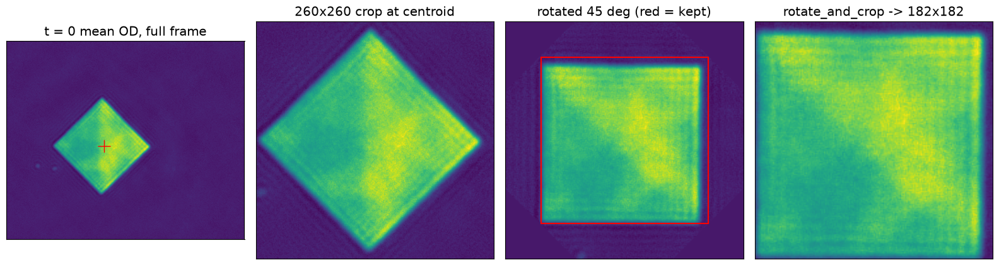

In [12]:
def mean_od(paths_, crop_box=None):
    return np.mean([ShotFile(p, cam=CAM, crop_box=crop_box).od for p in paths_], axis=0)


# sequence 6 is the t = 0 reference run
t0_paths = [p for p in paths if shot_time_ms(p) == 0.0]
m_full = mean_od(t0_paths)
print(f"t = 0 reference: {len(t0_paths)} shots, full frame {m_full.shape}")

_b = gaussian_filter(m_full, sigma=5)
_thr = np.sort(_b.ravel())[-int(_b.size * 0.10)]
_w = np.where(_b < _thr, 0.0, _b)
_sr, _sc = _w.sum(axis=1), _w.sum(axis=0)
CTR_ROW = int((np.arange(_w.shape[0]) * _sr).sum() / _sr.sum())
CTR_COL = int((np.arange(_w.shape[1]) * _sc).sum() / _sc.sum())

CROP_BOX = [CTR_ROW - CROP_HALF, CTR_ROW + CROP_HALF,
            CTR_COL - CROP_HALF, CTR_COL + CROP_HALF]
print(f"centroid (row, col) = ({CTR_ROW}, {CTR_COL})")
print(f"CROP_BOX = {CROP_BOX}")

# --- pixel-size sanity check: how wide is the box, in px? ---
_crop = m_full[CROP_BOX[0]:CROP_BOX[1], CROP_BOX[2]:CROP_BOX[3]]
_rot = rotate(_crop, ROT_ANGLE, reshape=False)
_widths = []
for _ax in (0, 1):
    _pr = _rot.sum(axis=_ax)
    _pr = _pr - np.median(np.r_[_pr[:10], _pr[-10:]])
    _i = np.where(_pr > _pr.max() * 0.35)[0]
    _widths.append(_i.max() - _i.min() + 1)
_wpx = np.mean(_widths)
print(f"box width = {_wpx:.0f} px  ->  {_wpx * PIXEL_UM:.1f} um at {PIXEL_UM} um/px"
      f"   (a 113 um box would need {113 / _wpx:.3f} um/px)")

# --- what the analysis window looks like ---
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
axes[0].imshow(m_full)
axes[0].plot(CTR_COL, CTR_ROW, "r+", ms=14)
axes[0].set_title("t = 0 mean OD, full frame")
axes[1].imshow(_crop)
axes[1].set_title(f"{_crop.shape[0]}x{_crop.shape[1]} crop at centroid")
_h = int(min(_crop.shape) / (2 * np.sqrt(2)))
axes[2].imshow(_rot)
axes[2].add_patch(plt.Rectangle((CROP_HALF - _h, CROP_HALF - _h), 2 * _h, 2 * _h,
                                fill=False, ec="r", lw=1.5))
axes[2].set_title(f"rotated {ROT_ANGLE} deg (red = kept)")
axes[3].imshow(rotate_and_crop(_crop))
axes[3].set_title(f"rotate_and_crop -> {2 * _h}x{2 * _h}")
for _a in axes:
    _a.set_xticks([])
    _a.set_yticks([])
fig.tight_layout()
plt.show()

In [13]:
# Build the image stack: one rotated/cropped OD per shot, tagged by time.
t_shots, _stack = [], []
for i, p in enumerate(paths):
    if i % 100 == 0:
        print(f"  {i}/{len(paths)}", flush=True)
    sf = ShotFile(p, cam=CAM, crop_box=CROP_BOX)
    t_shots.append(shot_time_ms(p))
    _stack.append(rotate_and_crop(sf.od))

t_shots = np.array(t_shots)
stack = np.stack(_stack)                 # [shot, x, y]
times = sorted(set(t_shots.tolist()))
del _stack

print(f"\nimage stack: {stack.shape}")
print(f"{len(times)} times, {t_shots.size} shots")
for _t in times:
    print(f"  t = {_t:8.1f} ms : {int((t_shots == _t).sum())} shots")

  0/729


  100/729
  200/729
  300/729
  400/729
  500/729
  600/729
  700/729

image stack: (729, 182, 182)
29 times, 729 shots
  t =      0.0 ms : 25 shots
  t =     20.0 ms : 25 shots
  t =     25.0 ms : 26 shots
  t =     30.0 ms : 25 shots
  t =     32.0 ms : 25 shots
  t =     34.0 ms : 25 shots
  t =     36.0 ms : 25 shots
  t =     38.0 ms : 25 shots
  t =     40.0 ms : 26 shots
  t =     45.0 ms : 26 shots
  t =     50.0 ms : 26 shots
  t =     60.0 ms : 25 shots
  t =     70.0 ms : 25 shots
  t =     80.0 ms : 25 shots
  t =     90.0 ms : 25 shots
  t =    100.0 ms : 25 shots
  t =    150.0 ms : 25 shots
  t =    200.0 ms : 25 shots
  t =    250.0 ms : 25 shots
  t =    300.0 ms : 25 shots
  t =    400.0 ms : 25 shots
  t =    500.0 ms : 25 shots
  t =    600.0 ms : 25 shots
  t =    700.0 ms : 25 shots
  t =    800.0 ms : 25 shots
  t =   1000.0 ms : 25 shots
  t =   1333.3 ms : 25 shots
  t =   1666.7 ms : 25 shots
  t =   2000.0 ms : 25 shots


In [14]:
# Same three functions as shot_images.ipynb, verbatim, so the two datasets
# are analysed identically.
def pca_svd(images):
    """Return normalized S^2 and spatial PCA vectors for images [shot, x, y]."""
    images = np.asarray(images, dtype=float)
    if images.ndim != 3:
        raise ValueError("images must have shape [shot, x, y]")
    pixels_by_shot = images.reshape(images.shape[0], -1).T
    vectors, singular_values, _ = np.linalg.svd(pixels_by_shot, full_matrices=False)
    eigenvalues = singular_values**2
    total = eigenvalues.sum()
    if total == 0:
        raise ValueError("images must have non-zero variance")
    eigenvalues /= total
    return eigenvalues, vectors.reshape(*images.shape[1:], -1)


def remove_pca_components(image, eigenvectors, n_components):
    """Return (cleaned, removed) after projecting image onto leading components."""
    image = np.asarray(image, dtype=float)
    eigenvectors = np.asarray(eigenvectors, dtype=float)
    if image.ndim != 2 or eigenvectors.shape[:2] != image.shape:
        raise ValueError("image and eigenvectors have incompatible shapes")
    if not 0 <= n_components <= eigenvectors.shape[-1]:
        raise ValueError("n_components is outside the available basis")
    basis = eigenvectors[..., :n_components].reshape(image.size, n_components)
    removed = (basis @ (basis.T @ image.ravel())).reshape(image.shape)
    return image - removed, removed


def _domain_length_raw(od):
    """L = 2 pi <S> / <k S> in px, only the uniform mode dropped."""
    S = np.abs(np.fft.fft2(od))**2
    S[0, 0] = 0.0
    ny, nx = od.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny)
    kx = 2 * np.pi * np.fft.fftfreq(nx)
    KX, KY = np.meshgrid(kx, ky, indexing="xy")
    return 2 * np.pi * S.sum() / (np.sqrt(KX**2 + KY**2) * S).sum()


# Per-time PCA: each time's shots get their OWN basis, so the envelope is
# tracked as it drifts over the 2 s of evolution.  ~25 samples per fit here.
pca_by_time = {_t: pca_svd(stack[t_shots == _t]) for _t in times}
print("per-time PCA done;  PC1 share of total variance:")
for _t in times:
    print(f"  t = {_t:8.1f} ms : {pca_by_time[_t][0][0]:.4f}")

per-time PCA done;  PC1 share of total variance:
  t =      0.0 ms : 0.9735
  t =     20.0 ms : 0.9559
  t =     25.0 ms : 0.9346
  t =     30.0 ms : 0.9231
  t =     32.0 ms : 0.9235
  t =     34.0 ms : 0.9106
  t =     36.0 ms : 0.8962
  t =     38.0 ms : 0.8959
  t =     40.0 ms : 0.8706
  t =     45.0 ms : 0.9019
  t =     50.0 ms : 0.8772
  t =     60.0 ms : 0.8734
  t =     70.0 ms : 0.8485
  t =     80.0 ms : 0.8534
  t =     90.0 ms : 0.8097
  t =    100.0 ms : 0.8482
  t =    150.0 ms : 0.7986
  t =    200.0 ms : 0.7601
  t =    250.0 ms : 0.7345
  t =    300.0 ms : 0.7313
  t =    400.0 ms : 0.7450
  t =    500.0 ms : 0.7220
  t =    600.0 ms : 0.7498
  t =    700.0 ms : 0.7591
  t =    800.0 ms : 0.7492
  t =   1000.0 ms : 0.7792
  t =   1333.3 ms : 0.7992
  t =   1666.7 ms : 0.7958
  t =   2000.0 ms : 0.8243


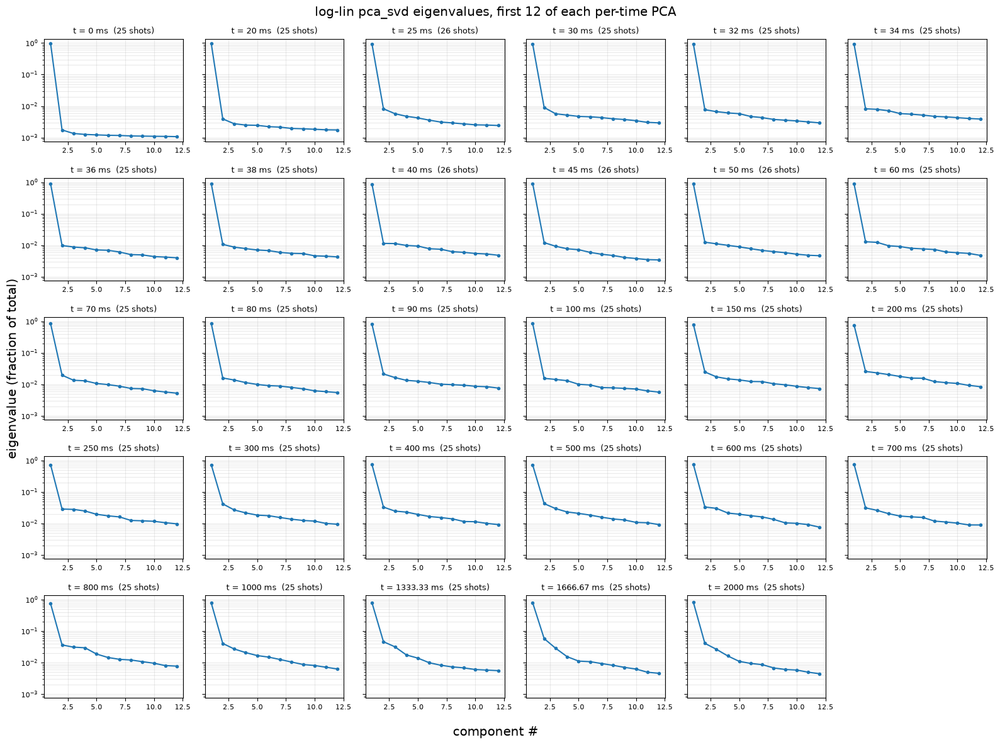

In [15]:
# Eigenvalue spectra, one panel per time (log-lin), as in shot_images cell 5.
N_EIG_SHOW = 12
ncols = 6
nrows = int(np.ceil(len(times) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(2.7 * ncols, 2.4 * nrows), sharey=True)
for ax, _t in zip(axes.ravel(), times):
    evals_t, _ = pca_by_time[_t]
    n = min(N_EIG_SHOW, len(evals_t))
    ax.semilogy(np.arange(1, n + 1), evals_t[:n], "o-", ms=3, color="C0")
    ax.set_title(f"t = {_t:g} ms  ({len(evals_t)} shots)", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.25, which="both")
for ax in axes.ravel()[len(times):]:
    ax.axis("off")
fig.supxlabel("component #")
fig.supylabel("eigenvalue (fraction of total)")
fig.suptitle(f"log-lin pca_svd eigenvalues, first {N_EIG_SHOW} of each per-time PCA")
fig.tight_layout()
plt.show()

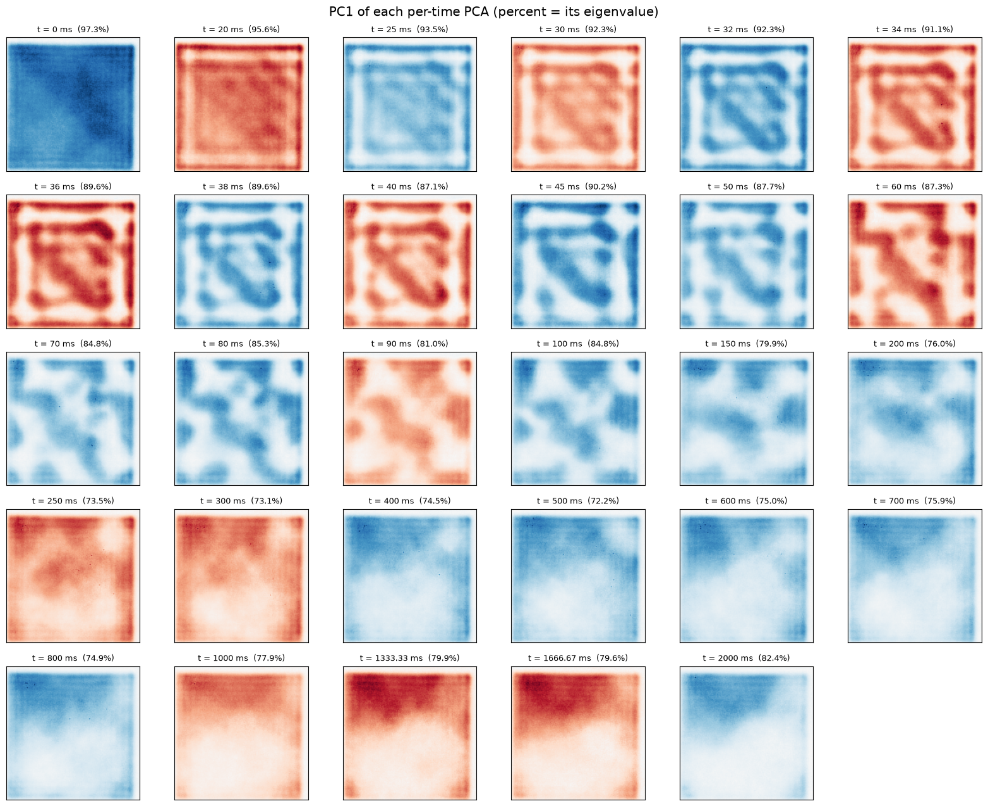

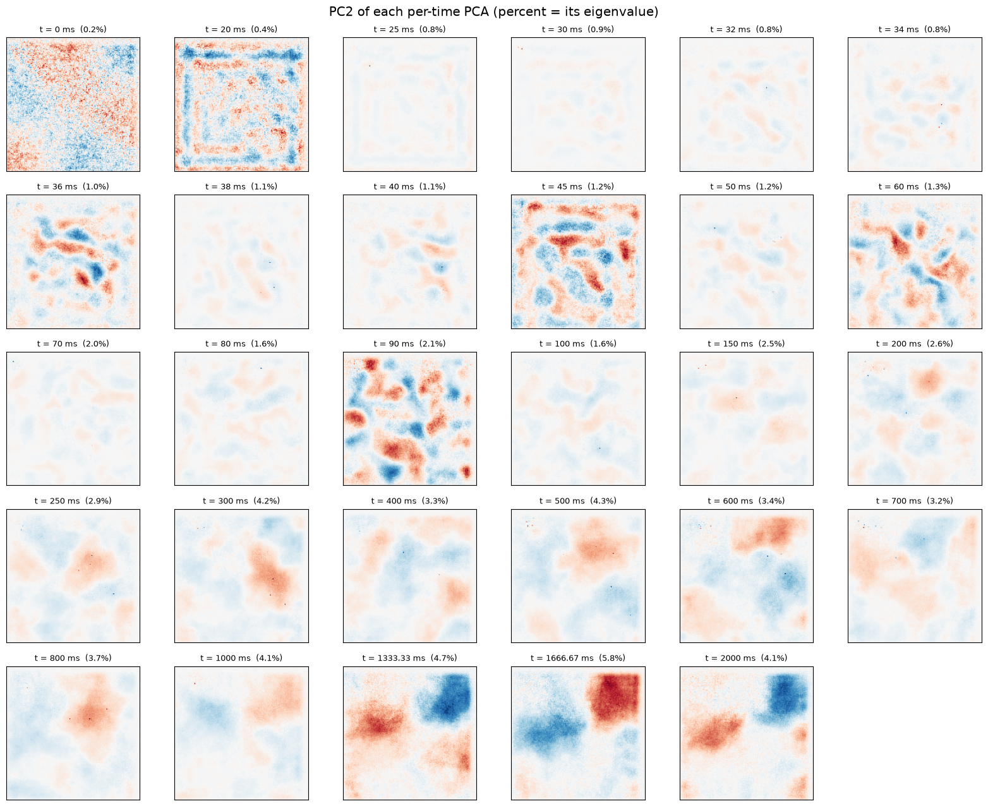

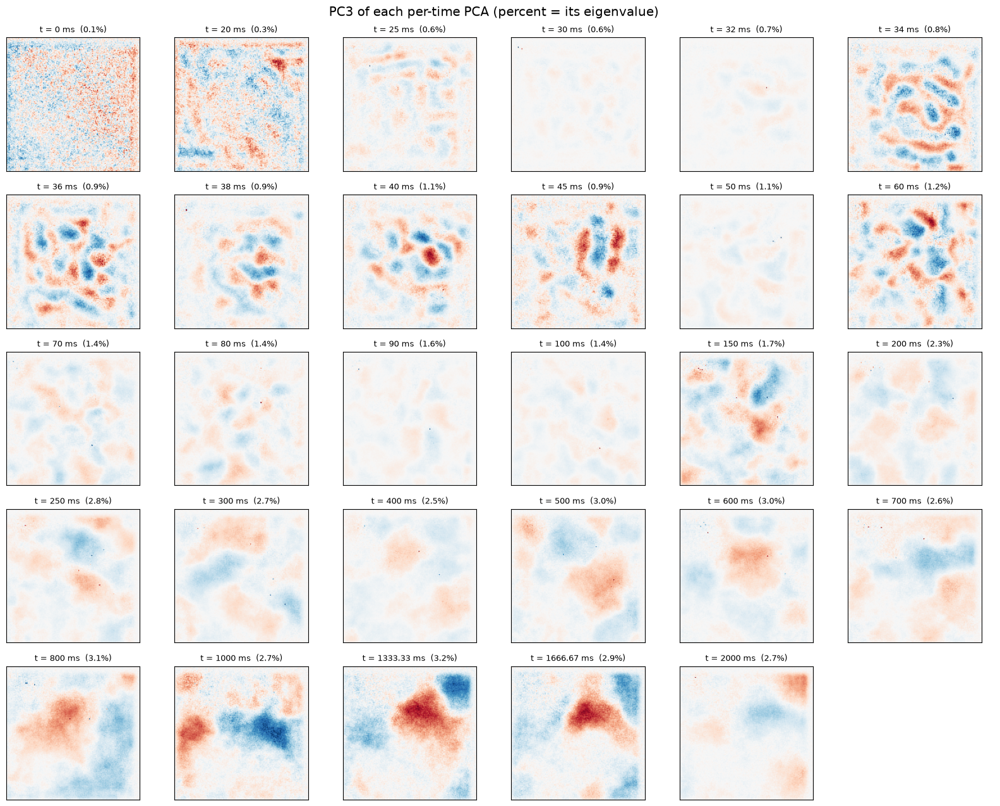

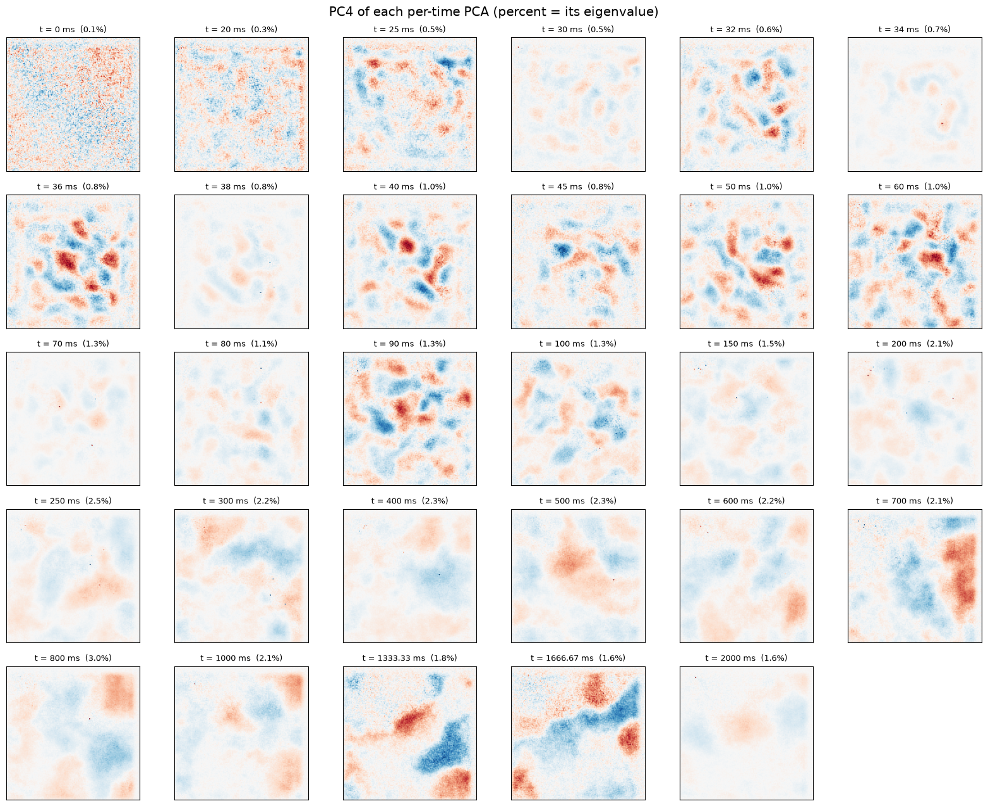

In [16]:
# The k-th eigenvector of each per-time PCA as an image, PC1..PC4.
ncols = 6
nrows = int(np.ceil(len(times) / ncols))
for k in range(4):
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.7 * ncols, 2.6 * nrows))
    for ax, _t in zip(axes.ravel(), times):
        evals_t, evecs_t = pca_by_time[_t]
        ax.set_xticks([])
        ax.set_yticks([])
        if k >= evecs_t.shape[-1]:
            ax.axis("off")
            continue
        comp = evecs_t[..., k]
        lim = np.abs(comp).max()
        ax.imshow(comp, cmap="RdBu_r", vmin=-lim, vmax=lim)
        ax.set_title(f"t = {_t:g} ms  ({evals_t[k]:.1%})", fontsize=9)
    for ax in axes.ravel()[len(times):]:
        ax.axis("off")
    fig.suptitle(f"PC{k + 1} of each per-time PCA (percent = its eigenvalue)")
    fig.tight_layout()
    plt.show()

In [17]:
# removes the first principal component of EACH TIME'S OWN PCA, NO window.
# L = 2 pi <S> / <k S> straight on the cleaned shot.
L_shots = np.empty(len(stack))
for _t in times:
    _m = t_shots == _t
    _, _pcs_t = pca_by_time[_t]
    L_shots[_m] = [_domain_length_raw(remove_pca_components(im, _pcs_t, 1)[0])
                   for im in stack[_m]]
L_shots *= PIXEL_UM

_tm = np.array(times, float)
L_mean = np.array([L_shots[t_shots == t].mean() for t in times])
L_sem = np.array([L_shots[t_shots == t].std(ddof=1)
                  / np.sqrt((t_shots == t).sum()) for t in times])

print(f"{'t (ms)':>9} {'n':>4} {'L (um)':>9} {'sem':>7}")
for i, t in enumerate(times):
    print(f"{t:9.1f} {int((t_shots == t).sum()):4d} {L_mean[i]:9.2f} {L_sem[i]:7.3f}")

   t (ms)    n    L (um)     sem
      0.0   25      2.54   0.017
     20.0   25      3.33   0.055
     25.0   26      4.24   0.145
     30.0   25      4.91   0.153
     32.0   25      5.54   0.231
     34.0   25      5.95   0.262
     36.0   25      6.65   0.238
     38.0   25      6.63   0.241
     40.0   26      7.40   0.187
     45.0   26      4.92   0.250
     50.0   26      7.43   0.244
     60.0   25      7.41   0.300
     70.0   25      7.86   0.338
     80.0   25      8.09   0.257
     90.0   25      9.29   0.299
    100.0   25      8.56   0.303
    150.0   25     10.66   0.377
    200.0   25     12.22   0.405
    250.0   25     13.43   0.296
    300.0   25     14.01   0.379
    400.0   25     13.06   0.470
    500.0   25     14.07   0.556
    600.0   25     12.96   0.468
    700.0   25     12.79   0.584
    800.0   25     14.34   0.648
   1000.0   25     11.20   0.563
   1333.3   25     10.27   0.538
   1666.7   25     10.31   0.635
   2000.0   25      9.02   0.483


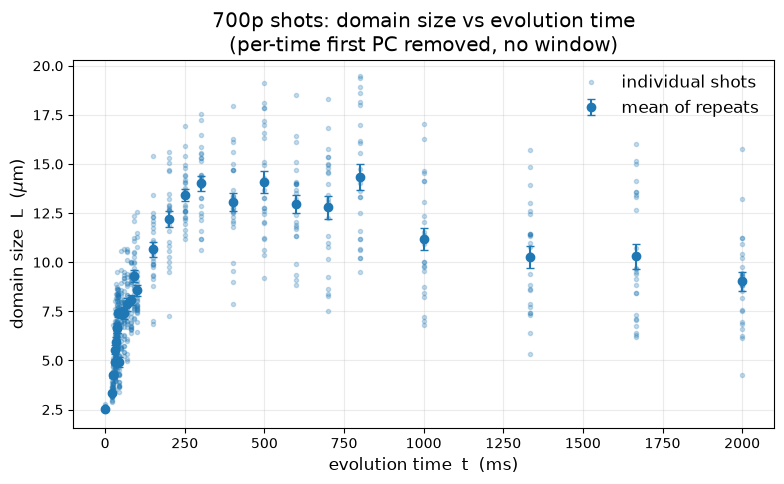

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_shots, L_shots, "o", ms=3, color="C0", alpha=0.25,
        label="individual shots")
ax.errorbar(_tm, L_mean, yerr=L_sem, fmt="o", ms=6, color="C0",
            capsize=3, label="mean of repeats", zorder=3)
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel(r"domain size  L  ($\mu$m)")
ax.set_title("700p shots: domain size vs evolution time\n(per-time first PC removed, no window)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [24]:
L_shots1 = np.empty(len(times[:31]))
for _t in times[:31]:
    _m = t_shots == _t
    _, _pcs_t = pca_by_time[_t]
    L_shots1[_m] = [_domain_length_raw(remove_pca_components(im, _pcs_t, 1)[0])
                   for im in stack[_m]]
L_shots1 *= PIXEL_UM

_tm = np.array(times, float)
L_mean = np.array([L_shots1[t_shots == t].mean() for t in times])
L_sem = np.array([L_shots1[t_shots == t].std(ddof=1)
                  / np.sqrt((t_shots == t).sum()) for t in times])

print(f"{'t (ms)':>9} {'n':>4} {'L (um)':>9} {'sem':>7}")
for i, t in enumerate(times[:31]):
    print(f"{t:9.1f} {int((t_shots == t).sum()):4d} {L_mean[i]:9.2f} {L_sem[i]:7.3f}")

IndexError: boolean index did not match indexed array along axis 0; size of axis is 29 but size of corresponding boolean axis is 729

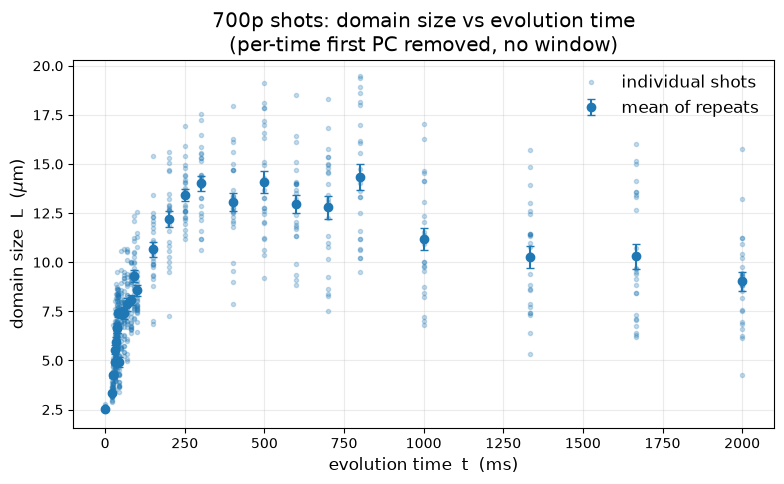

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_shots, L_shots, "o", ms=3, color="C0", alpha=0.25,
        label="individual shots")
ax.errorbar(_tm, L_mean, yerr=L_sem, fmt="o", ms=6, color="C0",
            capsize=3, label="mean of repeats", zorder=3)
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel(r"domain size  L  ($\mu$m)")
ax.set_title("700p shots: domain size vs evolution time\n(per-time first PC removed, no window)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

free power-law fits  L ~ t^n :
     20-  100 ms  (n_pts=15) :  n = 0.530
     30-  300 ms  (n_pts=17) :  n = 0.408
     20-  800 ms  (n_pts=24) :  n = 0.339


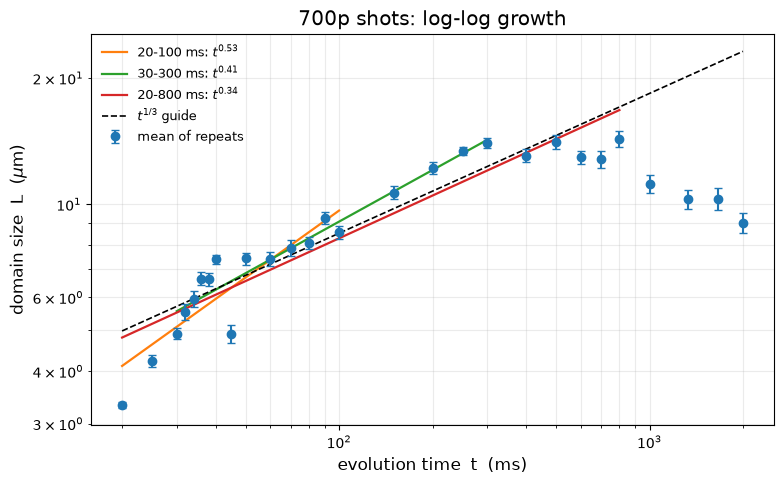

In [ ]:
# log-log, with free power-law fits over a few windows and a t^(1/3) guide.
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(_tm[_tm > 0], L_mean[_tm > 0], yerr=L_sem[_tm > 0], fmt="o", ms=6,
            color="C0", capsize=3, label="mean of repeats", zorder=3)

print("free power-law fits  L ~ t^n :")
for (lo, hi), c in zip([(20, 100), (30, 300), (20, 800)], ["C1", "C2", "C3"]):
    s = (_tm >= lo) & (_tm <= hi)
    n, logA = np.polyfit(np.log(_tm[s]), np.log(L_mean[s]), 1)
    print(f"  {lo:5.0f}-{hi:5.0f} ms  (n_pts={s.sum():2d}) :  n = {n:.3f}")
    ax.plot(_tm[s], np.exp(logA) * _tm[s]**n, "-", color=c, lw=1.6,
            label=f"{lo}-{hi} ms: $t^{{{n:.2f}}}$")

_s13 = (_tm >= 20) & (_tm <= 300)
_A = np.exp(np.mean(np.log(L_mean[_s13]) - np.log(_tm[_s13]) / 3))
ax.plot(_tm[_tm > 0], _A * _tm[_tm > 0]**(1 / 3), "k--", lw=1.2, label=r"$t^{1/3}$ guide")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel(r"domain size  L  ($\mu$m)")
ax.set_title("700p shots: log-log growth")
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.25, which="both")
fig.tight_layout()
plt.show()

## Robustness

Two things were chosen by hand above: the analysis window (the inscribed square
is slightly wider than the box) and removing exactly one component. This sweeps
both. If the numbers move a lot here, the growth exponent is an artefact of
those choices rather than a measurement.

In [ ]:
rot_full = np.stack([rotate(ShotFile(p, cam=CAM, crop_box=CROP_BOX).od,
                             ROT_ANGLE, reshape=False) for p in paths])

def sweep(half, n_pc):
    c = rot_full.shape[1] // 2
    st = rot_full[:, c - half:c + half, c - half:c + half]
    L = np.empty(len(st))
    for t in times:
        m = t_shots == t
        _, pcs = pca_svd(st[m])
        L[m] = [_domain_length_raw(remove_pca_components(im, pcs, n_pc)[0]) for im in st[m]]
    L *= PIXEL_UM
    return np.array([L[t_shots == t].mean() for t in times])

print(f"{'window':>10} {'nPC':>4} | {'L(0)':>6} {'L(40)':>6} {'L(300)':>7} {'L(2000)':>8} |"
      f" {'n(20-100)':>10} {'n(30-300)':>10}")
for half in (91, 84, 75):
    for n_pc in (1, 2, 3):
        m = sweep(half, n_pc)
        e1 = np.polyfit(np.log(_tm[(_tm >= 20) & (_tm <= 100)]),
                        np.log(m[(_tm >= 20) & (_tm <= 100)]), 1)[0]
        e2 = np.polyfit(np.log(_tm[(_tm >= 30) & (_tm <= 300)]),
                        np.log(m[(_tm >= 30) & (_tm <= 300)]), 1)[0]
        idx = lambda v: times.index(v)
        print(f"{2 * half:10d} {n_pc:4d} | {m[0]:6.2f} {m[idx(40.0)]:6.2f} "
              f"{m[idx(300.0)]:7.2f} {m[idx(2000.0)]:8.2f} | {e1:10.3f} {e2:10.3f}")

    window  nPC |   L(0)  L(40)  L(300)  L(2000) |  n(20-100)  n(30-300)
       182    1 |   2.54   7.40   14.01     9.02 |      0.530      0.408
       182    2 |   2.48   7.15   12.72     7.37 |      0.534      0.393
       182    3 |   2.46   6.88   11.93     6.41 |      0.523      0.376
       168    1 |   2.54   7.72   14.08     9.24 |      0.526      0.389
       168    2 |   2.48   7.45   12.75     7.49 |      0.528      0.373
       168    3 |   2.46   7.16   11.94     6.48 |      0.519      0.356
       150    1 |   2.50   8.36   13.94     8.94 |      0.518      0.347
       150    2 |   2.46   8.06   12.52     7.06 |      0.518      0.328
       150    3 |   2.44   7.73   11.65     6.15 |      0.510      0.311


## Things to look at

- **t = 45 ms sits well below its neighbours** (~4.9 um against ~7.4 um at both
  40 and 50 ms). That is sequence 21, taken on its own after the rest; worth
  checking whether that run had different loading before trusting the point.
- **L turns over after ~300-800 ms** and falls by 2000 ms. The box is ~113 um
  and L only reaches ~14 um, so this is not domains hitting the wall -- more
  likely contrast loss as atoms are lost, which drags L down through the
  high-k noise floor.
- **L(t = 0) = 2.5 um** is the noise floor (~4 px), which is the sanity check
  that PC1 removal is taking the envelope out properly.

---

## 2026-09-11 shots: cropped OD only (no PC removed, no window)

New run (`data/raw/2026-09-11`, dataset `sep11`): 692 usable shots over 24 hold
times from 0 to 2000 ms, 26-30 shots per time. It is framed exactly like the 700p
set above (centroid of the t = 0 mean, `CROP_HALF` square, `rotate_and_crop`),
but `L = 2 pi <S> / <k S>` goes straight onto the cropped OD: **no PC is
removed and no window is applied**.

Because nothing is subtracted, the box envelope and walls add to `S(k)`, so
`L(t = 0)` sits near 9 um instead of the ~2.5 um noise floor you get after PC1
removal. Compare these numbers with other no-PC results only. The 700p set is
drawn in grey for reference, run through the same estimator.

In [ ]:
# This notebook's first cell still imports the pre-restructure
# `quantum_sim.file`; pull the current loader and the dataset registry here.
from quantum_sim.config import dataset
from quantum_sim.io import ShotFile

# 2026-09-11 run: domain size vs evolution time, NO PC removed and NO window.
# Same crop as the 700p analysis above: centroid of the blurred t = 0 mean,
# CROP_HALF square around it, then rotate_and_crop. L = 2 pi <S> / <k S> goes
# straight onto that cropped OD, with only the k = 0 mode dropped.
SEP11_DIR = str(dataset("sep11").path)

sep11_paths = []
for _p in sorted(glob.glob(os.path.join(SEP11_DIR, "*bec_box2*.h5"))):
    if not NAME_RE.match(os.path.basename(_p)):
        continue
    with h5py.File(_p, "r") as _f:
        if "images" in _f:                 # skip aborted shots (no frames)
            sep11_paths.append(_p)
print(f"2026-09-11: {len(sep11_paths)} usable shots")

# locate the cloud from this run's own t = 0 shots
_m11 = mean_od([p for p in sep11_paths if shot_time_ms(p) == 0.0])
_b = gaussian_filter(_m11, sigma=5)
_w = np.where(_b < np.sort(_b.ravel())[-int(_b.size * 0.10)], 0.0, _b)
_sr, _sc = _w.sum(axis=1), _w.sum(axis=0)
_r = int((np.arange(_w.shape[0]) * _sr).sum() / _sr.sum())
_c = int((np.arange(_w.shape[1]) * _sc).sum() / _sc.sum())
CROP_BOX_11 = [_r - CROP_HALF, _r + CROP_HALF, _c - CROP_HALF, _c + CROP_HALF]
print(f"centroid (row, col) = ({_r}, {_c})  ->  CROP_BOX_11 = {CROP_BOX_11}")

t_shots_11 = np.array([shot_time_ms(p) for p in sep11_paths])
stack_11 = np.stack([rotate_and_crop(ShotFile(p, cam=CAM, crop_box=CROP_BOX_11).od)
                     for p in sep11_paths])
times_11 = sorted(set(t_shots_11.tolist()))

L_raw_11 = np.array([_domain_length_raw(im) for im in stack_11]) * PIXEL_UM
_tm11 = np.array(times_11, float)
L_mean_11 = np.array([L_raw_11[t_shots_11 == t].mean() for t in times_11])
L_sem_11 = np.array([L_raw_11[t_shots_11 == t].std(ddof=1)
                     / np.sqrt((t_shots_11 == t).sum()) for t in times_11])

# the 700p stack through the identical no-PC / no-window estimator, for reference
L_raw_700 = np.array([_domain_length_raw(im) for im in stack]) * PIXEL_UM
L_mean_700 = np.array([L_raw_700[t_shots == t].mean() for t in times])

print(f"{'t (ms)':>9} {'n':>4} {'L (um)':>9} {'sem':>7}")
for i, t in enumerate(times_11):
    print(f"{t:9.1f} {int((t_shots_11 == t).sum()):4d} {L_mean_11[i]:9.2f} {L_sem_11[i]:7.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_shots_11, L_raw_11, "o", ms=3, color="C0", alpha=0.25,
        label="2026-09-11, individual shots")
ax.errorbar(_tm11, L_mean_11, yerr=L_sem_11, fmt="o", ms=6, color="C0",
            capsize=3, label="2026-09-11, mean of repeats", zorder=3)
ax.plot(times, L_mean_700, "s--", ms=4, lw=1, color="0.55",
        label="700p (2026-08-19), mean, same estimator")
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel(r"domain size  L  ($\mu$m)")
ax.set_title("2026-09-11 shots: domain size vs evolution time\n"
             "(cropped OD only: no PC removed, no window)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
SEP11_FIG = dataset("sep11").figure("domain_size_vs_time_no_pc.png")
fig.savefig(SEP11_FIG, dpi=150)
print(f"saved {SEP11_FIG}")
plt.show()